### Dependnecy Setup

In [51]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import pyomo.environ as pyo

### Load Data

In [52]:
# Choose dataset B or C
DATA = "B"

In [53]:
df_gen_params = pd.read_csv(f'Data/Data{DATA}_generatorparams.csv', sep=';')
df_load = pd.read_csv(f'Data/Data{DATA}_hourlyload.csv', sep=';')
df_nondisp = pd.read_csv(f'Data/Data{DATA}_nondispgeneration.csv', sep=';')

# If DataC is in MW, convert to kW
# I BELIEVE!
if DATA == "C":
    df_gen_params[['pmin', 'pmax']] *= 1000  # MW → kW
    df_load['load'] *= 1000  # MWh → kWh

## Parse the data

### Sample multiple solar- and wind scenarios

In [54]:
# Change to test where optimality is guaranteed
num_scenarios = 20

In [55]:
# 1. Helper function to parse '0-5' into [0, 1, 2, 3, 4, 5]
def parse_hour_block(block_str):
    start, end = map(int, block_str.split('-'))
    return list(range(start, end + 1))

# 2. Create a lookup map: Hour (0-23)
hour_dist_map = {}
for block in df_nondisp['hour'].unique():
    hours_in_block = parse_hour_block(block)
    dist_rows = df_nondisp[df_nondisp['hour'] == block]
    for h in hours_in_block:
        hour_dist_map[h] = dist_rows

# 3. Generate Scenarios
np.random.seed(42) # Fixed seed for reproducibility
scenario_data = {} # This will store our data for the Pyomo model

for s in range(num_scenarios):
    # Lists to store the 24-hour profile for this specific scenario
    wind_profile = []
    solar_profile = []
    
    for h in range(24):
        dist = hour_dist_map[h]
        
        # Sample Wind
        # Normalize probs to avoid floating point errors (e.g., sum=0.999999)
        w_probs = dist['probability wind'].values / dist['probability wind'].values.sum()
        w_val = np.random.choice(dist['generation wind'].values, p=w_probs)
        wind_profile.append(w_val)
        
        # Sample Solar
        s_probs = dist['probability solar'].values / dist['probability solar'].values.sum()
        s_val = np.random.choice(dist['generation solar'].values, p=s_probs)
        solar_profile.append(s_val)
    
    # Store as a DataFrame (convenient for Pyomo indexing)
    scenario_data[s] = pd.DataFrame({
        'wind': wind_profile, 
        'solar': solar_profile
    })

# Check scenario
print(scenario_data[1])

    wind  solar
0     40      0
1    200      0
2    200      0
3     40      0
4     20      0
5     20      0
6     40     40
7    100     40
8     20     60
9     20     90
10    20     90
11   100     10
12    20    200
13   100    200
14   100     10
15    40     10
16   100     60
17    40     10
18    40     40
19   100     60
20   100      0
21    20      0
22   100      0
23   100      0


### Model Initialization

In [56]:
model = pyo.ConcreteModel(name="Unit Commitment Stage 1")

# Sets
model.S = pyo.Set(initialize=range(20)) # Sample over 20 scenarios

# Generators [1, 2, 3]
model.G = pyo.Set(initialize=df_gen_params['generator'].tolist())

# Time steps [0, 1, ..., 23]
model.T = pyo.Set(initialize=hourly_data.index.tolist())

### Parameters

In [57]:
# Parameters for Generators 
model.a1 = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['a1'].to_dict())
model.a2 = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['a2'].to_dict())
model.p_min = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['pmin'].to_dict())
model.p_max = pyo.Param(model.G, initialize=df_gen_params.set_index('generator')['pmax'].to_dict())

# Parameters for Hourly Data 
model.hourly_load = pyo.Param(model.T, initialize=hourly_data['load'].to_dict())

# Build initializer dicts for Pyomo Params
wind_init = {(t, s): scenario_data[s].loc[t, 'wind'] for s in model.S for t in model.T}
solar_init = {(t, s): scenario_data[s].loc[t, 'solar'] for s in model.S for t in model.T}

# Define Params with these initializers
model.wind_samples = pyo.Param(model.T, model.S, initialize=wind_init, within=pyo.NonNegativeReals)
model.solar_samples = pyo.Param(model.T, model.S, initialize=solar_init, within=pyo.NonNegativeReals)

### Decision Variables

In [58]:
# u[g, t]: Binary status of dispatchable generator g at time t (1 if on, 0 if off)
model.u = pyo.Var(model.G, model.T, domain=pyo.Binary)

# p[g, t]: Power output of dispatchable generator g at time t (non-negative) in scenario S
model.p = pyo.Var(model.G, model.T, model.S, domain=pyo.NonNegativeReals)

# u_wind[t], u_solar[t]: Binary status of non-dispatchable generators at time t
model.u_wind = pyo.Var(model.T, domain=pyo.Binary)
model.u_solar = pyo.Var(model.T, domain=pyo.Binary)

## Slack Variables

In [59]:
# surplus[t], deficit[t]: Surplus and deficit variables at time t 
# to ensure feasibility if production does not equal demand
model.surplus = pyo.Var(model.T, model.S, domain=pyo.NonNegativeReals)
model.deficit = pyo.Var(model.T, model.S, domain=pyo.NonNegativeReals)

### Objective Function
Minimize the cost of power generators averaged over the scenarios S

In [60]:
def objective_rule(m):
    total_expected_cost = 0
    for s in m.S:
        generation_cost = sum(m.a2[g] * m.p[g,t,s]**2 + m.a1[g] * m.p[g,t,s] for g in m.G for t in m.T)
        penalty_cost = sum(1000 * (m.surplus[t,s] + m.deficit[t,s]) for t in m.T)
        total_expected_cost += (generation_cost + penalty_cost)
    return total_expected_cost / len(m.S)
model.obj = pyo.Objective(rule=objective_rule, sense=pyo.minimize)

### Constraints

In [61]:
# Minimum Generation
def p_min_rule(m, g, t, s):
    return m.p[g, t, s] >= m.u[g, t] * m.p_min[g]
model.C_p_min = pyo.Constraint(model.G, model.T, model.S, rule=p_min_rule)

# Maximum Generation
def p_max_rule(m, g, t, s):
    return m.p[g, t, s] <= m.u[g, t] * m.p_max[g]
model.C_p_max = pyo.Constraint(model.G, model.T, model.S, rule=p_max_rule)

# Power Balance
def p_balance_rule(m, t, s):
    dispatchable_gen = sum(m.p[g, t, s] for g in m.G)
    nondispatchable_gen = (m.u_wind[t] * m.wind_samples[t, s]) + (m.u_solar[t] * m.solar_samples[t, s])

    return dispatchable_gen + nondispatchable_gen + m.surplus[t, s] - m.deficit[t, s] == m.hourly_load[t]
model.C_p_balance = pyo.Constraint(model.T, model.S, rule=p_balance_rule)

### Solving with NEOS

In [62]:
# Setup Solver Manager
solver_manager = pyo.SolverManagerFactory('neos')

# Select Solver
solver_name = 'cplex' 

# Your email address (required for NEOS)
os.environ['NEOS_EMAIL'] = 'jonas.streuff@tum.de'

print(f"Sending model to NEOS using {solver_name}...")

# Send to NEOS
results = solver_manager.solve(model, opt=solver_name)
print(f"Solver Status: {results.solver.status}")
print(f"Termination Condition: {results.solver.termination_condition}")

# If successful, we extract the results
if results.solver.termination_condition == pyo.TerminationCondition.optimal:
    print("Optimal solution found.")
else:
    print("Warning: Optimal solution not found.")


Sending model to NEOS using cplex...
Solver Status: ok
Termination Condition: optimal
Optimal solution found.


### Print Results

In [66]:
def get_timeseries(variable, generator_idx=None, is_binary=False, has_scenarios=False):
    def val_or_number(x):
        return x.value if hasattr(x, "value") else x

    data = []
    for t in sorted(model.T):
        if has_scenarios:
            # Average across all scenarios
            if generator_idx is not None:
                val = sum(val_or_number(variable[generator_idx, t, s]) or 0 for s in model.S) / len(model.S)
            else:
                val = sum(val_or_number(variable[t, s]) or 0 for s in model.S) / len(model.S)
        else:
            if generator_idx is not None:
                val = val_or_number(variable[generator_idx, t])
            else:
                val = val_or_number(variable[t])

        if val is None:
            val = 0.0
        if is_binary:
            val = round(val)
        data.append(val)
    return data

load_data = [model.hourly_load[t] for t in sorted(model.T)]
wind_avg = get_timeseries(model.wind_samples, has_scenarios=True)
solar_avg = get_timeseries(model.solar_samples, has_scenarios=True)

u_wind = get_timeseries(model.u_wind, is_binary=True)
u_solar = get_timeseries(model.u_solar, is_binary=True)

gen_ids = sorted(model.G)
p_gen_data = {}
u_gen_data = {}

for g in gen_ids:
    p_gen_data[g] = get_timeseries(model.p, generator_idx=g, has_scenarios=True)
    u_gen_data[g] = get_timeseries(model.u, generator_idx=g, is_binary=True)

# 3. Print the Formatted Table
print("\n" + "="*90)
print(f"OPTIMIZATION RESULTS - Total Cost: {pyo.value(model.obj):,.2f} €")
print("="*90)

# Build Header
# Fixed Columns
header = f"{'Hr':<3} | {'Load':<6} | {'Wind':<5} {'U':<2} | {'Solar':<5} {'U':<2} | "
# Dynamic Columns (one pair per generator)
for g in gen_ids:
    header += f"G{g} (P)   G{g}(U) | "
print(header)
print("-" * len(header))

# Print Rows
for t in range(24):
    # Base Data (Load + Renewables)
    # We cast to int/float for clean formatting
    row = (f"{t:<3} | {load_data[t]:<6.0f} | "
           f"{wind_avg[t]:<5.0f} {int(u_wind[t]):<2} | "
           f"{solar_avg[t]:<5.0f} {int(u_solar[t]):<2} | ")

    # Generator Data
    for g in gen_ids:
        p_val = p_gen_data[g][t]
        u_val = int(u_gen_data[g][t])

        # Visual cleanup: if generator is OFF, show Power as 0.0
        if u_val == 0:
            p_val = 0.0

        row += f"{p_val:<8.1f} {u_val:<5} | "

    print(row)

print("-" * len(header))


OPTIMIZATION RESULTS - Total Cost: 410,034.33 €
Hr  | Load   | Wind  U  | Solar U  | G1 (P)   G1(U) | G2 (P)   G2(U) | G3 (P)   G3(U) | 
----------------------------------------------------------------------------------------
0   | 496    | 65    1  | 0     0  | 265.4    1     | 0.0      0     | 165.6    1     | 
1   | 476    | 54    1  | 0     0  | 260.2    1     | 0.0      0     | 161.8    1     | 
2   | 468    | 62    1  | 0     0  | 251.1    1     | 0.0      0     | 154.9    1     | 
3   | 472    | 77    1  | 0     0  | 245.9    1     | 0.0      0     | 149.1    1     | 
4   | 486    | 71    1  | 0     0  | 256.7    1     | 0.0      0     | 158.3    1     | 
5   | 520    | 45    1  | 0     0  | 289.2    1     | 0.0      0     | 185.8    1     | 
6   | 584    | 70    1  | 46    1  | 288.3    1     | 0.0      0     | 179.2    1     | 
7   | 622    | 42    0  | 56    1  | 235.3    1     | 180.0    1     | 150.2    1     | 
8   | 655    | 54    1  | 48    1  | 236.3    1     | 180.0  

### Plot Results

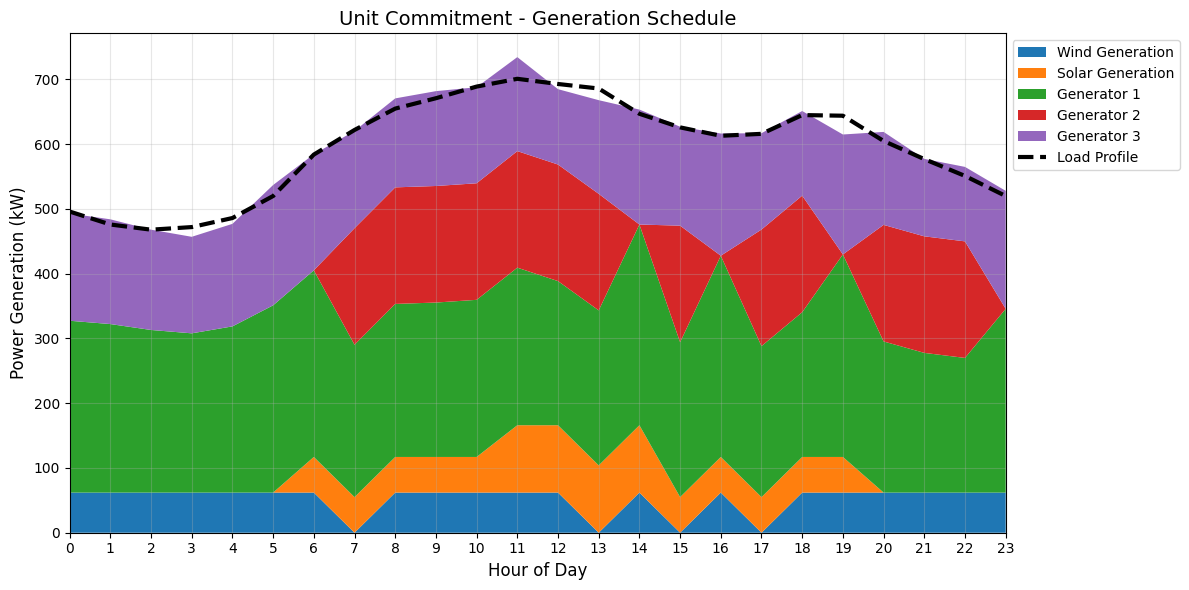

In [67]:
hours = sorted(model.T)

# Dispatchable Generation
wind_gen = []
solar_gen = []
dispatchable_gen = {g: [] for g in gen_ids}

for t in hours:
    wind_gen.append(u_wind[t] * wind_exp[t])
    solar_gen.append(u_solar[t] * solar_exp[t])

    for g in gen_ids:
        dispatchable_gen[g].append(p_gen_data[g][t])


plt.figure(figsize=(12,6))

plt.stackplot(hours, wind_gen, solar_gen, dispatchable_gen[1], dispatchable_gen[2], dispatchable_gen[3],
              labels=['Wind Generation', 'Solar Generation', 'Generator 1', 'Generator 2', 'Generator 3'],
              colors=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'])

plt.plot(hours, load_data, color='black', linewidth=3, label='Load Profile', linestyle='--')

plt.title("Unit Commitment - Generation Schedule", fontsize=14)
plt.xlabel("Hour of Day", fontsize=12)
plt.ylabel("Power Generation (kW)", fontsize=12)
plt.xlim(0, 23)
plt.xticks(hours)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()